# E-14 Document AI & ETL Pipeline | Fase 2: Visión Artificial, OCR/HTR/OMR y Carga ACID

Notebook de demostración e inspección del pipeline de procesamiento de actas electorales E-14 (Segunda Vuelta Presidencial 2026):
1. **Alineación geométrica y binarización** (`PyMuPDF` + `OpenCV`).
2. **Segmentación de ROIs** (encabezados, 27 casillas manuscritas y 17 zonas OMR).
3. **Inferencia híbrida** (`EasyOCR` para texto impreso, `TrOCR` para manuscritos y densidad de píxeles OMR).
4. **Persistencia atómica en Supabase** con 12 banderas granulares de auditoría (`revision_banderas`) y log en CSV.

## 1. Instalación de Dependencias (Solo Google Colab)

In [2]:
import sys

IS_COLAB = "google.colab" in sys.modules
if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip install -q pymupdf opencv-python-headless "transformers==4.46.3" sentencepiece easyocr supabase python-dotenv

## 2. Configuración del Entorno e Importación de Módulos (`src/`)

In [3]:
from pathlib import Path

import pymupdf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ajuste automático de la raíz del proyecto según el entorno de ejecución
PROJECT_ROOT = (
    Path("/content/drive/MyDrive/Elecciones2_2026_PDFs/e14")
    if IS_COLAB
    else Path.cwd().parent
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.processing.ocr import (
    extract_e14_ocr_data,
    load_easyocr_reader,
    load_trocr_resources,
    read_text_region,
)
from src.processing.pipeline import (
    evaluate_review_flags,
    execute_ocr_pipeline,
    resolve_station_id,
)
from src.processing.tools import (
    clean_float,
    consolidate_digits,
    parse_divipole_text,
    process_e14_form,
    scan_e14_pdfs,
)
from src.processing.view import plot_roi_dictionary, plot_three_cells

c:\Users\miggi\Documents\.e14\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Indexación del Universo de Formularios PDF (`data/`)

In [4]:
PDF_DIR = PROJECT_ROOT / "data"

df_e14 = scan_e14_pdfs(PDF_DIR)
print(f"Total formularios E-14 indexados: {len(df_e14)}")
df_e14.head()

Total formularios E-14 indexados: 383


,dd,mm,zz,pp,mesa,path
0,01,001,02,02,029,G:\Mi unidad\Elecciones2_2026_PDFs\e14\data\01...
1,01,001,06,02,037,G:\Mi unidad\Elecciones2_2026_PDFs\e14\data\01...
2,01,001,09,05,021,G:\Mi unidad\Elecciones2_2026_PDFs\e14\data\01...
3,01,001,10,03,011,G:\Mi unidad\Elecciones2_2026_PDFs\e14\data\01...
4,01,001,11,04,006,G:\Mi unidad\Elecciones2_2026_PDFs\e14\data\01...


## 4. Carga Única de Modelos en Memoria (`TrOCR` + `EasyOCR`)

In [5]:
device, processor, model, vocab_token_ids = load_trocr_resources()
reader = load_easyocr_reader()

Loading weights: 100%|██████████| 478/478 [00:00<00:00, 3342.11it/s]
[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 5. Demostración Visual (1 Acta): Alineación Geométrica y Segmentación de ROIs

Inspeccionando acta de muestra: 01_001_02_02_029.pdf


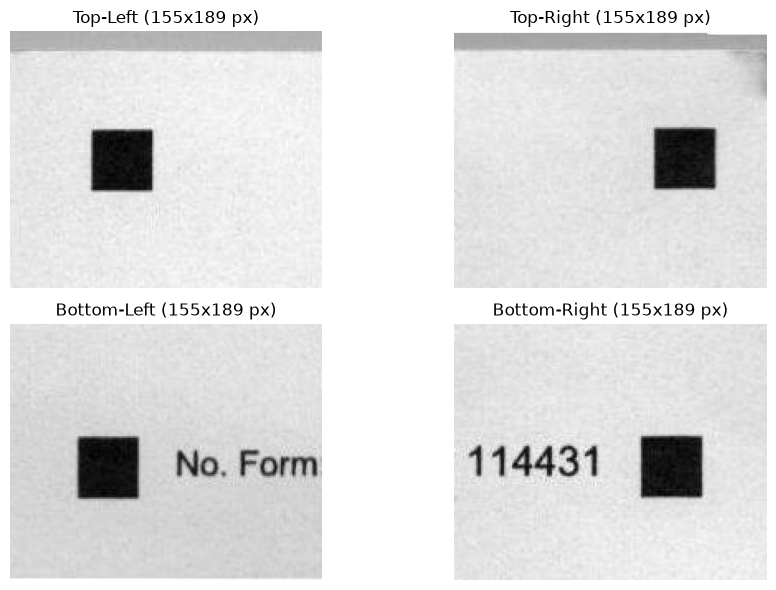

Dimensiones de la imagen: Alto = 3897, Ancho = 1260


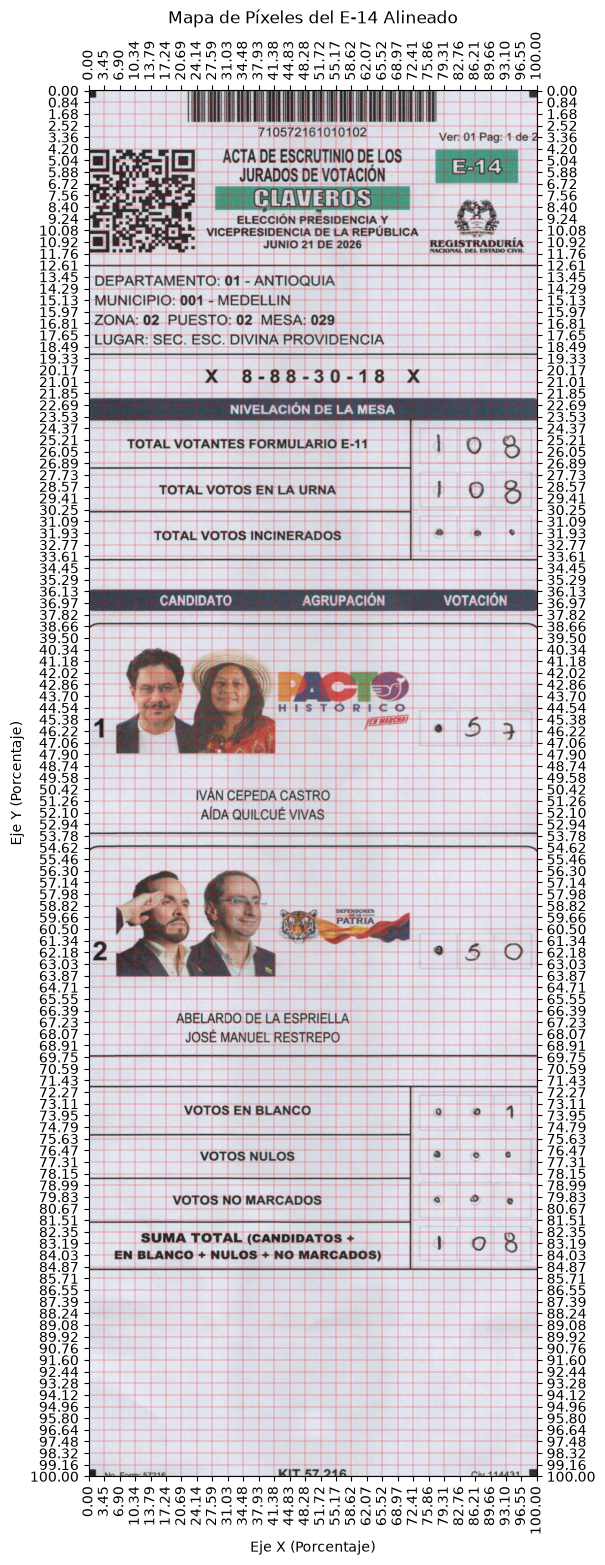

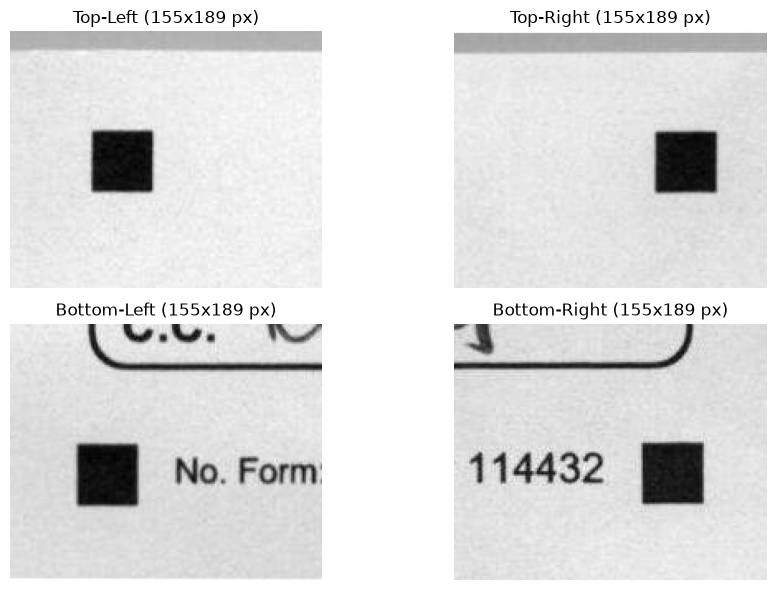

Dimensiones de la imagen: Alto = 3897, Ancho = 1260


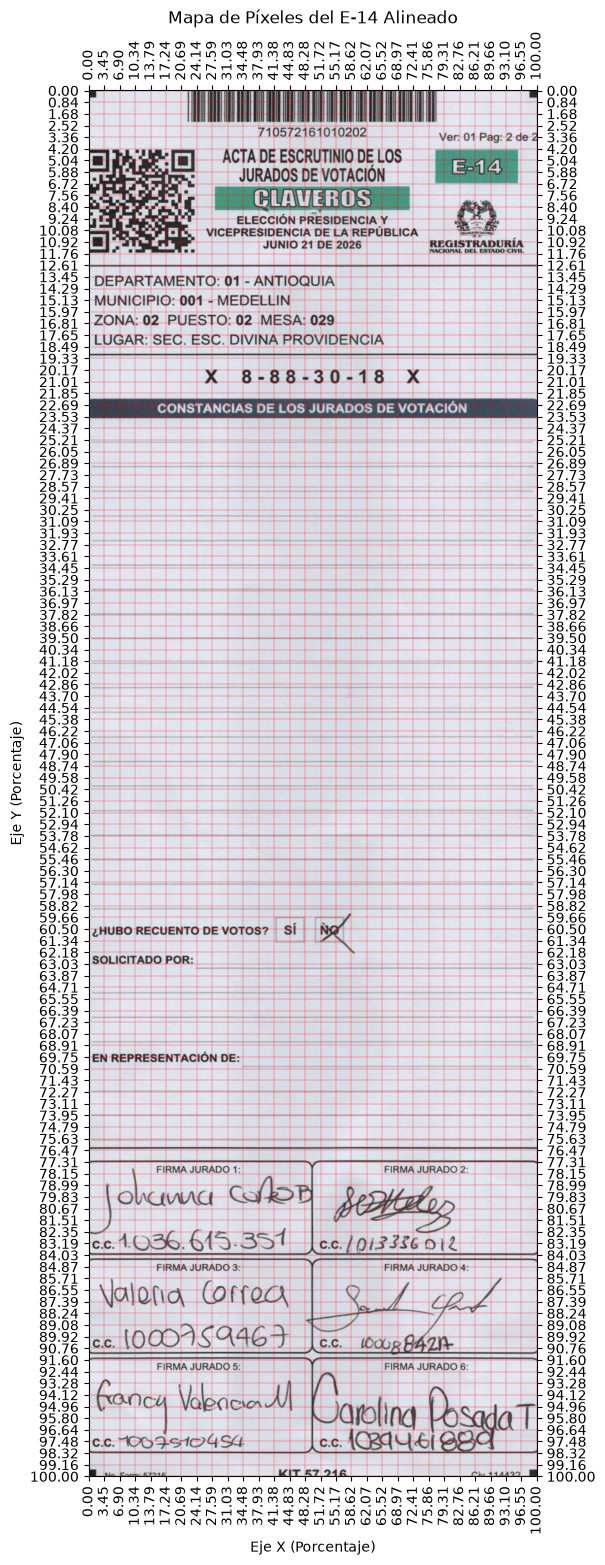

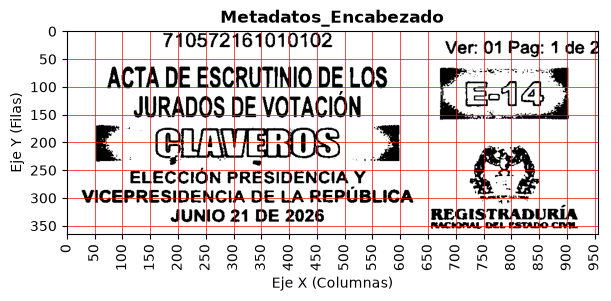

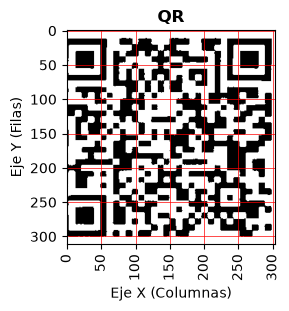

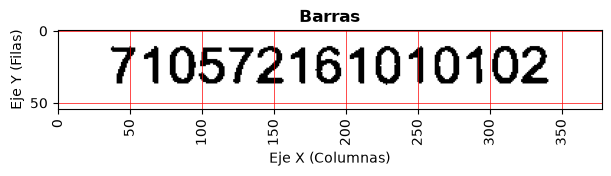

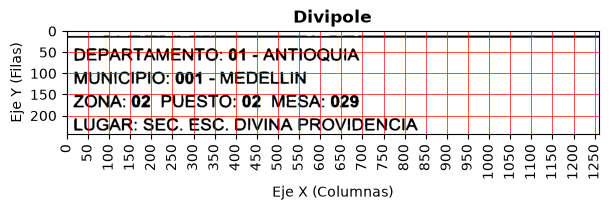

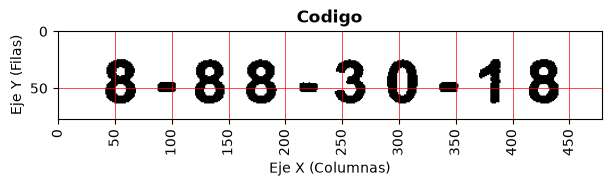

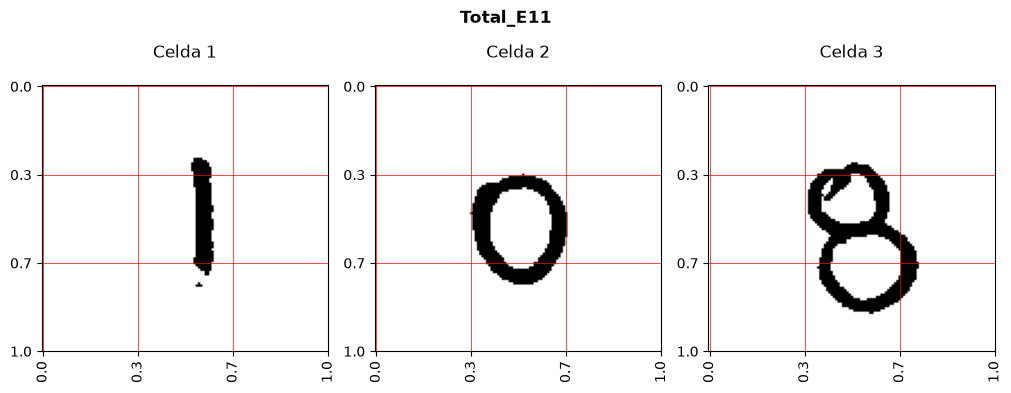

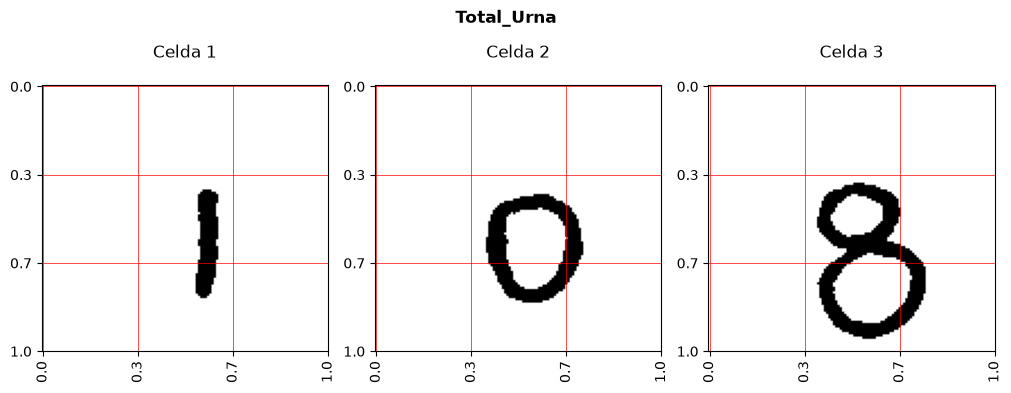

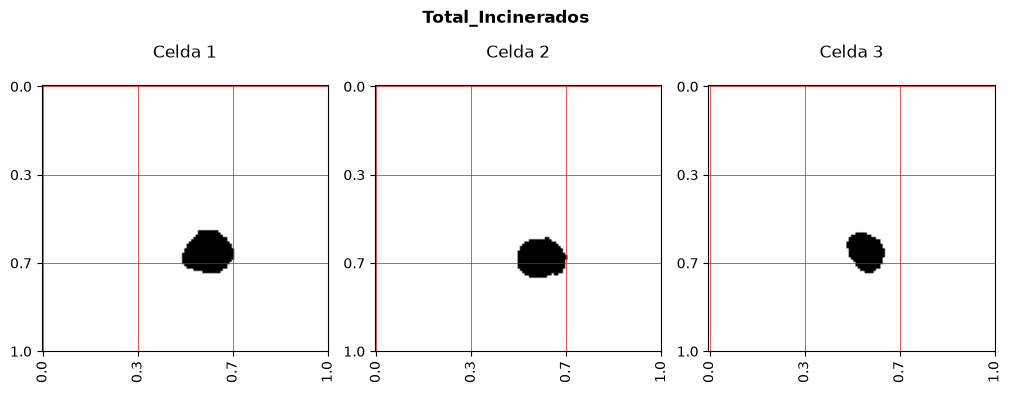

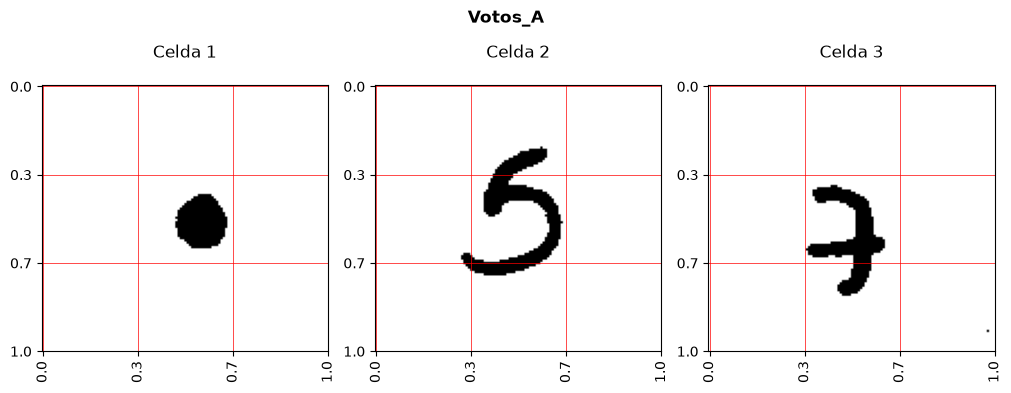

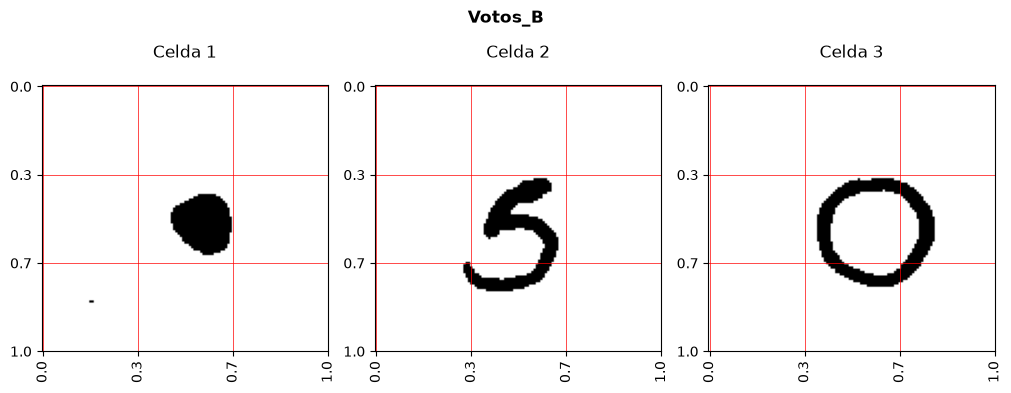

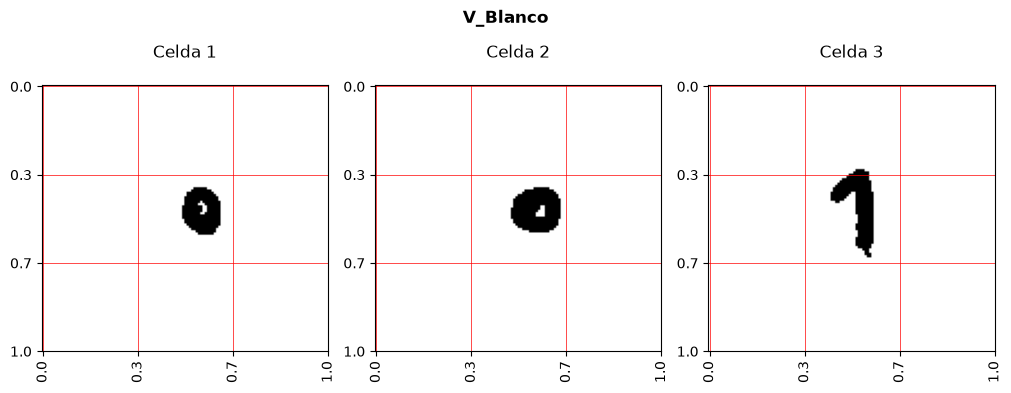

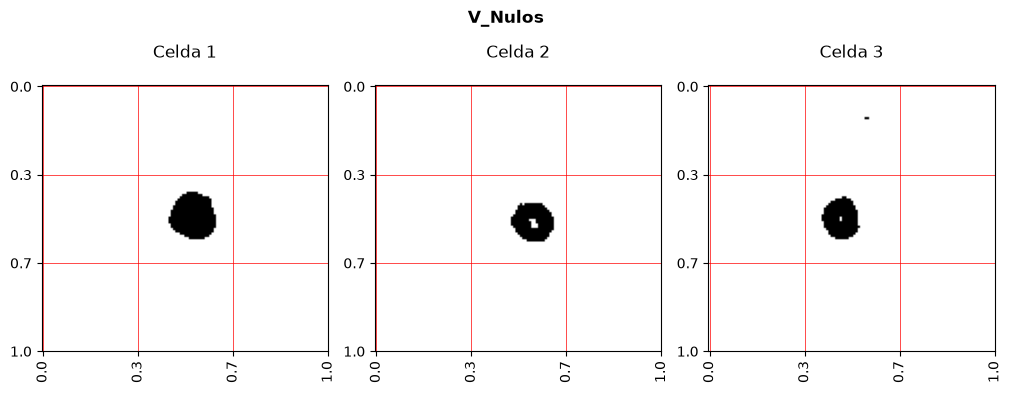

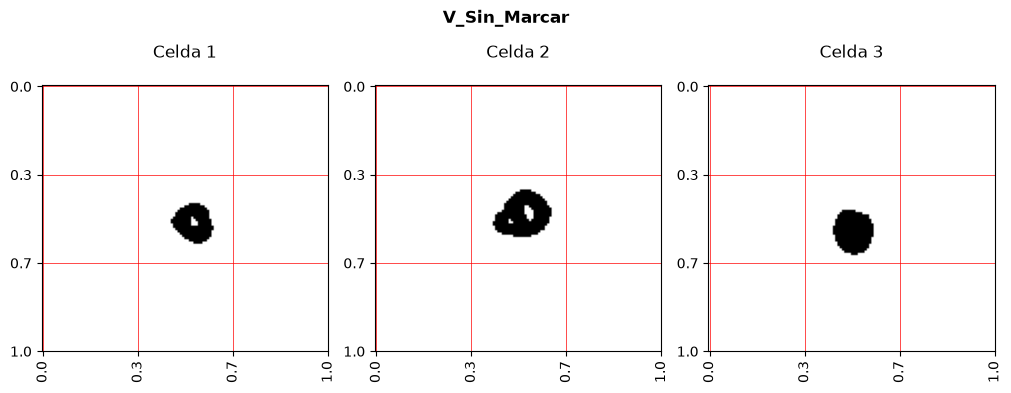

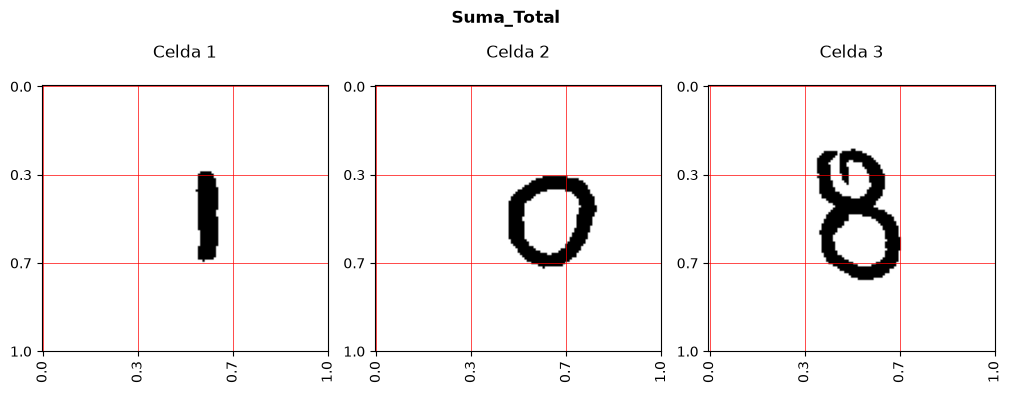

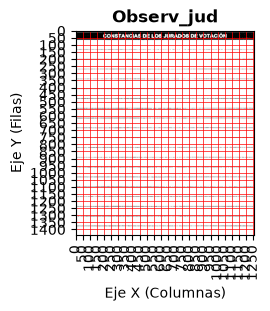

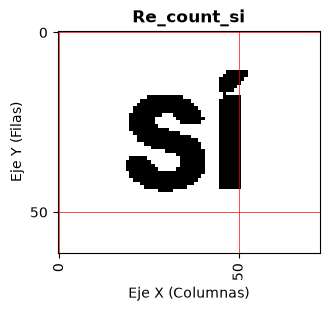

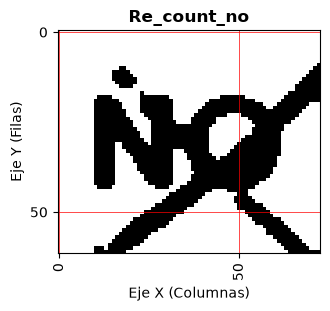

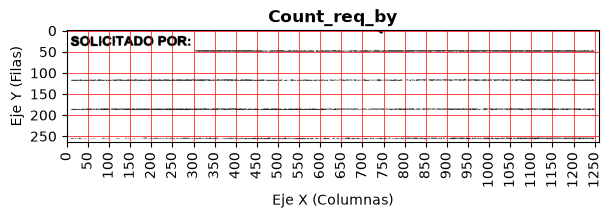

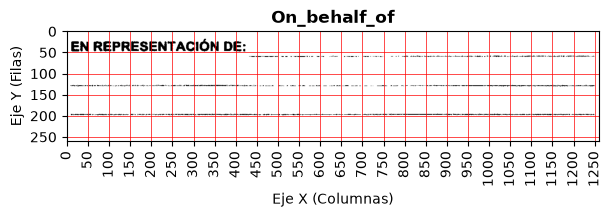

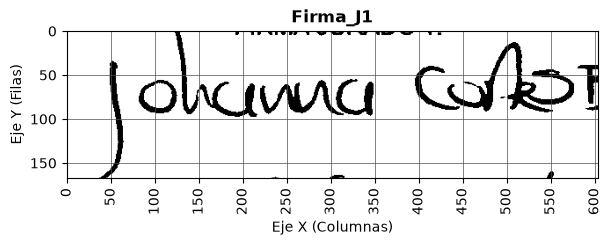

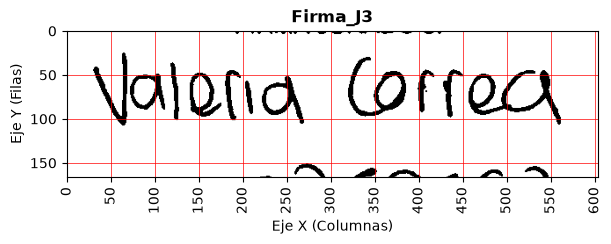

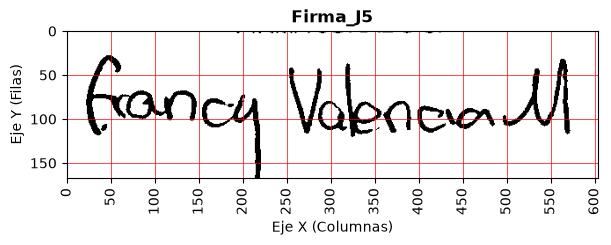

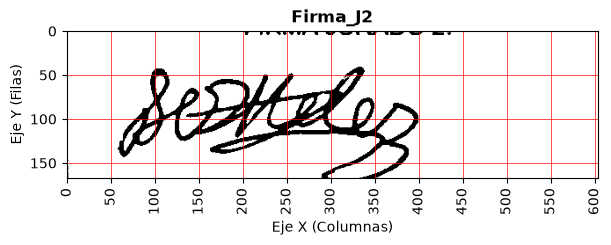

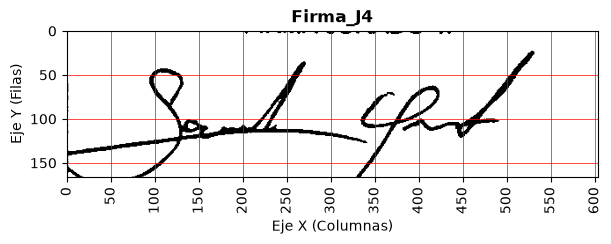

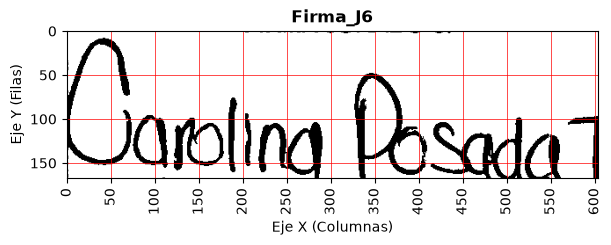

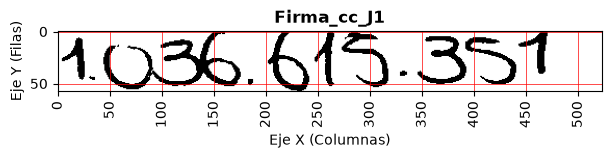

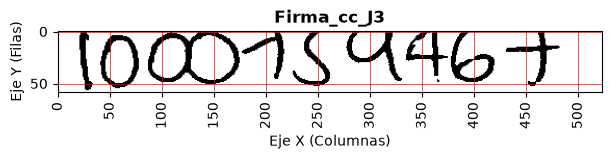

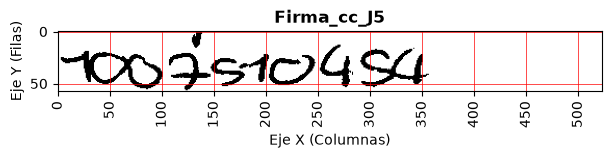

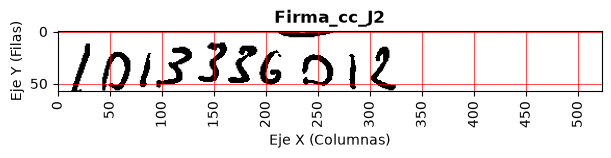

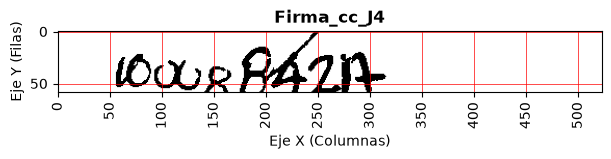

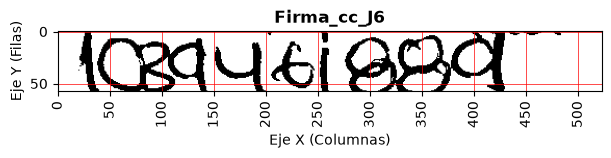

In [6]:
sample_pdf_path = df_e14.iloc[0]["path"]
print(f"Inspeccionando acta de muestra: {Path(sample_pdf_path).name}")

# debug=True grafica las 4 marcas fiduciarias y la página alineada con grilla porcentual
sample_rois = process_e14_form(sample_pdf_path, debug=True)
assert sample_rois is not None, "El acta de muestra falló la alineación geométrica."

# Visualización de regiones extraídas (encabezado, casillas manuscritas y OMR)
plot_roi_dictionary(sample_rois[0])  # Encabezado Página 1
plot_roi_dictionary(sample_rois[2])  # Casillas triples de votación Página 1
plot_roi_dictionary(sample_rois[3])  # Zonas OMR y firmas Página 2

## 6. Demostración Visual (1 Acta): Extracción OCR / HTR / OMR

In [7]:
sample_ocr_data, sample_divipole = extract_e14_ocr_data(
    sample_rois, reader, device, vocab_token_ids, processor, model
)
print("Metadatos DIVIPOLE extraídos:", sample_divipole)
pd.Series(sample_ocr_data).to_frame(name="Valor_Extraido")

Metadatos DIVIPOLE extraídos: {'DP_Dept': '01', 'DP_Munp': '001', 'DP_Zona': '02', 'DP_Psto': '02', 'DP_Mesa': '029', 'DP_Lugr': 'SEC. ESC. DIVINA PROVIDENCIA'}


,Valor_Extraido
manual,False
Codigo,8883018
s_codigo,0.565505
Codigo_2,8883018
s_codigo_2,0.384282
...,...
Firma_cc_J3,"(True, 17.91)"
Firma_cc_J5,"(True, 12.77)"
Firma_cc_J2,"(True, 12.09)"
Firma_cc_J4,"(True, 11.98)"


## 7. Ejecución Batch End-to-End y Persistencia Atómica en Supabase

Ejecuta el pipeline completo sobre todos los PDFs indexados, aplicando las 12 banderas de auditoría, transacciones ACID vía RPC en PostgreSQL y registro de incidencias en `data/errores_procesamiento.csv`.

In [8]:
resumen_metricas = execute_ocr_pipeline(pdf_root_dir=PDF_DIR)

[FASE 2] Directorio: g:\Mi unidad\Elecciones2_2026_PDFs\e14\data
[FASE 2] Total formularios PDF indexados: 383
[CACHE] Mapa de puestos cargado en memoria: 13,489 puestos indexados.
[ESTADO DE COLA]
 - Formularios completos en BD     : 377
 - Puestos con registros existentes: 337
 - Puestos totalmente pendientes   : 13,152
[FASE 2] Inicializando modelos TrOCR y EasyOCR en memoria...


Loading weights: 100%|██████████| 478/478 [00:00<00:00, 3992.20it/s]
[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



[=== INICIO DE PROCESAMIENTO POR LOTES ===]
[1/383] [SALTADO] '01_001_02_02_029' ya completo en Supabase.
[2/383] [SALTADO] '01_001_06_02_037' ya completo en Supabase.
[3/383] [SALTADO] '01_001_09_05_021' ya completo en Supabase.
[4/383] [SALTADO] '01_001_10_03_011' ya completo en Supabase.
[5/383] [SALTADO] '01_001_11_04_006' ya completo en Supabase.
[6/383] [SALTADO] '01_001_13_06_016' ya completo en Supabase.
[7/383] [SALTADO] '01_001_15_09_005' ya completo en Supabase.
[8/383] [SALTADO] '01_001_16_01_014' ya completo en Supabase.
[9/383] [SALTADO] '01_001_16_06_002' ya completo en Supabase.
[10/383] [SALTADO] '01_001_19_01_027' ya completo en Supabase.
[11/383] [SALTADO] '01_001_20_01_010' ya completo en Supabase.
[12/383] [SALTADO] '01_001_20_02_013' ya completo en Supabase.
[13/383] [SALTADO] '01_001_20_03_007' ya completo en Supabase.
[14/383] [SALTADO] '01_001_21_05_008' ya completo en Supabase.
[15/383] [SALTADO] '01_001_28_03_003' ya completo en Supabase.
[16/383] [SALTADO] 

## 8. Inspector Visual de Diagnóstico por Acta Individual

Herramienta de auditoría para inspeccionar visualmente cualquier formulario marcado con banderas de revisión o fallo geométrico.

In [13]:
def inspect_e14_pdf(query: str | int) -> None:
    """Inspecciona geométrica, visual y estadísticamente un acta E-14 específica.

    Args:
        query (str | int): Nombre completo/parcial del archivo (ej. '01_172_00_00_016')
            o posición 1-based dentro de `df_e14` (ej. 43).
    """
    assert "df_e14" in globals(), "Ejecuta primero la Celda 3 para indexar df_e14."
    assert "model" in globals() and "reader" in globals(), "Ejecuta primero la Celda 4 para cargar los modelos."

    # 1. Resolución del archivo objetivo dentro de df_e14
    if isinstance(query, int):
        if not (1 <= query <= len(df_e14)):
            raise IndexError(f"Número fuera de rango: {query} (debe estar entre 1 y {len(df_e14)}).")
        row = df_e14.iloc[query - 1]
        log_pos = query
    else:
        matches = df_e14[df_e14["path"].str.contains(str(query), case=False, regex=False)]
        if matches.empty:
            raise FileNotFoundError(f"No se encontró ningún PDF que coincida con '{query}'.")
        if len(matches) > 1:
            print(f"[AVISO] {len(matches)} coincidencias; mostrando la primera:")
            print(matches["path"].apply(lambda p: Path(p).name).head(5).to_string())
        row = matches.iloc[0]
        log_pos = int(matches.index[0]) + 1

    pdf_path = Path(row["path"])
    source_file = pdf_path.stem

    with pymupdf.open(str(pdf_path)) as doc:
        num_pages = len(doc)

    print("=" * 75)
    print(f"INSPECTOR E-14 | [{log_pos}/{len(df_e14)}] {pdf_path.name} | Páginas: {num_pages}")
    print("=" * 75)

    # 2. Alineación geométrica con visualización de esquinas y grilla (debug=True)
    print("\n[1/4] ALINEACIÓN GEOMÉTRICA Y MARCAS FIDUCIARIAS:")
    rois_list = process_e14_form(pdf_path, debug=True)

    if rois_list is None:
        print("\n[FALLO DE ALINEACIÓN - err_alineacion=True]")
        print("Revisa las 4 esquinas graficadas arriba para identificar qué marca fiduciaria falló.")
        return

    # 3. Inferencia OCR / HTR / OMR y evaluación de banderas
    print("\n[2/4] EJECUTANDO INFERENCIA OCR / HTR / OMR...")
    ocr_data, divipole_p1 = extract_e14_ocr_data(
        rois_list, reader, device, vocab_token_ids, processor, model
    )
    divipole_p2 = parse_divipole_text(read_text_region(rois_list[1]["Divipole"], reader))

    if ocr_data is None:
        print("\n[FALLO DE INFERENCIA - err_inferencia_ocr=True] Se mostrarán únicamente los recortes.")
    else:
        votes_mapping = {
            "t_e11": ("Total_E11_1", "Total_E11_2", "Total_E11_3"),
            "t_urna": ("Total_Urna_1", "Total_Urna_2", "Total_Urna_3"),
            "t_inc": ("Total_Incinerados_1", "Total_Incinerados_2", "Total_Incinerados_3"),
            "v_a": ("Votos_A_1", "Votos_A_2", "Votos_A_3"),
            "v_b": ("Votos_B_1", "Votos_B_2", "Votos_B_3"),
            "v_blan": ("V_Blanco_1", "V_Blanco_2", "V_Blanco_3"),
            "v_nulo": ("V_Nulos_1", "V_Nulos_2", "V_Nulos_3"),
            "v_s_mrc": ("V_Sin_Marcar_1", "V_Sin_Marcar_2", "V_Sin_Marcar_3"),
            "suma_t": ("Suma_Total_1", "Suma_Total_2", "Suma_Total_3"),
        }

        consolidated_totals = {}
        vote_cells_info = []
        vp_confs = []
        for db_field, (k1, k2, k3) in votes_mapping.items():
            consolidated_totals[db_field] = consolidate_digits(
                str(ocr_data.get(k1, "0")),
                str(ocr_data.get(k2, "0")),
                str(ocr_data.get(k3, "0")),
            )
            for key in (k1, k2, k3):
                pred = str(ocr_data.get(key, ""))[:10]
                conf = clean_float(ocr_data.get(f"s_{key}", 0.0))
                vp_confs.append(conf)
                vote_cells_info.append((key, pred, conf))

        avg_conf = clean_float(np.mean(vp_confs)) if vp_confs else 0.0

        audit_mapping = {
            "observ_jud": "Observ_jud", "re_count_si": "Re_count_si", "re_count_no": "Re_count_no",
            "count_req_by": "Count_req_by", "on_behalf_of": "On_behalf_of",
            "firma_j1": "Firma_J1", "firma_j2": "Firma_J2", "firma_j3": "Firma_J3",
            "firma_j4": "Firma_J4", "firma_j5": "Firma_J5", "firma_j6": "Firma_J6",
            "firma_cc_j1": "Firma_cc_J1", "firma_cc_j2": "Firma_cc_J2", "firma_cc_j3": "Firma_cc_J3",
            "firma_cc_j4": "Firma_cc_J4", "firma_cc_j5": "Firma_cc_J5", "firma_cc_j6": "Firma_cc_J6",
        }
        aud_bools = {
            db_f: bool(ocr_data.get(k, (False, 0.0))[0]) for db_f, k in audit_mapping.items()
        }

        station_id = resolve_station_id(stations_map, divipole_p1) if "stations_map" in globals() else -1
        flags, details = evaluate_review_flags(
            source_file=source_file,
            ocr_data=ocr_data,
            station_id=None if station_id is None else station_id,
            consolidated_totals=consolidated_totals,
            avg_confidence=avg_conf,
            vote_cells_info=vote_cells_info,
            aud_bools=aud_bools,
        )
        if "stations_map" not in globals():
            flags["err_puesto_no_resuelto"] = False

        print("\n--- DIAGNÓSTICO DE BANDERAS ---")
        active = [k for k, v in flags.items() if v]
        if not active:
            print("[OK] Acta LIMPIA (0 banderas activas).")
        else:
            for flag_name in active:
                print(f"  [FLAG] {flag_name}: {details.get(flag_name, 'Activa')}")

        print("\n--- ENCABEZADO Y DIVIPOLE LEÍDO ---")
        print(f"  Pág 1     : {divipole_p1}")
        print(f"  Pág 2     : {divipole_p2}")
        print(
            f"  Código P1 : '{ocr_data.get('Codigo')}' (s={clean_float(ocr_data.get('s_codigo'))}) | "
            f"Código P2 : '{ocr_data.get('Codigo_2')}' (s={clean_float(ocr_data.get('s_codigo_2'))})"
        )
        print(
            f"  Barras_1  : '{ocr_data.get('Barras_1')}' (s={clean_float(ocr_data.get('s_barras_1'))}) | "
            f"Barras_2  : '{ocr_data.get('Barras_2')}' (s={clean_float(ocr_data.get('s_barras_2'))})"
        )
        print(f"  Totales   : {consolidated_totals} | Promedio TrOCR: {avg_conf:.2f}")

    # 4. Visualización etiquetada de encabezados (Pág. 1 y Pág. 2)
    print("\n[3/4] CAPTURAS DE ENCABEZADOS (PÁG. 1 Y PÁG. 2):")
    header_items = [
        ("Pág 1 - Divipole", rois_list[0]["Divipole"]),
        ("Pág 2 - Divipole", rois_list[1]["Divipole"]),
        ("Pág 1 - Código", rois_list[0]["Codigo"]),
        ("Pág 2 - Código_2", rois_list[1]["Codigo"]),
        ("Pág 1 - Barras_1", rois_list[0]["Barras"]),
        ("Pág 2 - Barras_2", rois_list[1]["Barras"]),
    ]
    fig, axes = plt.subplots(3, 2, figsize=(14, 7), layout="constrained")
    for ax, (title, img) in zip(axes.flat, header_items):
        ax.imshow(img, cmap="gray")
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.axis("off")
    plt.show()

    # 5. Visualización de casillas manuscritas de votación (Pág. 1)
    print("\n[4/4] CAPTURAS DE VOTOS MANUSCRITOS (PÁG. 1) Y AUDITORÍA OMR (PÁG. 2):")
    row_prefixes = [
        ("Total_E11", "t_e11"), ("Total_Urna", "t_urna"), ("Total_Incinerados", "t_inc"),
        ("Votos_A", "v_a"), ("Votos_B", "v_b"), ("V_Blanco", "v_blan"),
        ("V_Nulos", "v_nulo"), ("V_Sin_Marcar", "v_s_mrc"), ("Suma_Total", "suma_t"),
    ]
    for prefix, db_field in row_prefixes:
        if ocr_data:
            preds_str = " | ".join(
                f"{ocr_data.get(f'{prefix}_{i}')} ({clean_float(ocr_data.get(f's_{prefix}_{i}')):.2f})"
                for i in (1, 2, 3)
            )
            title = f"{prefix} -> [{preds_str}] => {consolidated_totals[db_field]}"
        else:
            title = prefix
        plot_three_cells(
            rois_list[2][f"{prefix}_1"],
            rois_list[2][f"{prefix}_2"],
            rois_list[2][f"{prefix}_3"],
            title=title,
        )

    # 6. Visualización de casillas OMR y firmas (Pág. 2)
    omr_items = list(rois_list[3].items())
    n_cols = 3
    n_rows = int(np.ceil(len(omr_items) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 2.4), layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    for ax, (k, crop) in zip(axes.flat, omr_items):
        ax.imshow(crop, cmap="gray")
        if ocr_data and k in ocr_data:
            state, pct = ocr_data[k]
            ax.set_title(f"{k}: {state} ({pct}%)", fontsize=9, fontweight="bold")
        else:
            ax.set_title(k, fontsize=9)
        ax.axis("on")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle("Regiones OMR y Firmas - Página 2", fontweight="bold", fontsize=12)
    plt.show()

INSPECTOR E-14 | [1/383] 01_001_02_02_029.pdf | Páginas: 2

[1/4] ALINEACIÓN GEOMÉTRICA Y MARCAS FIDUCIARIAS:


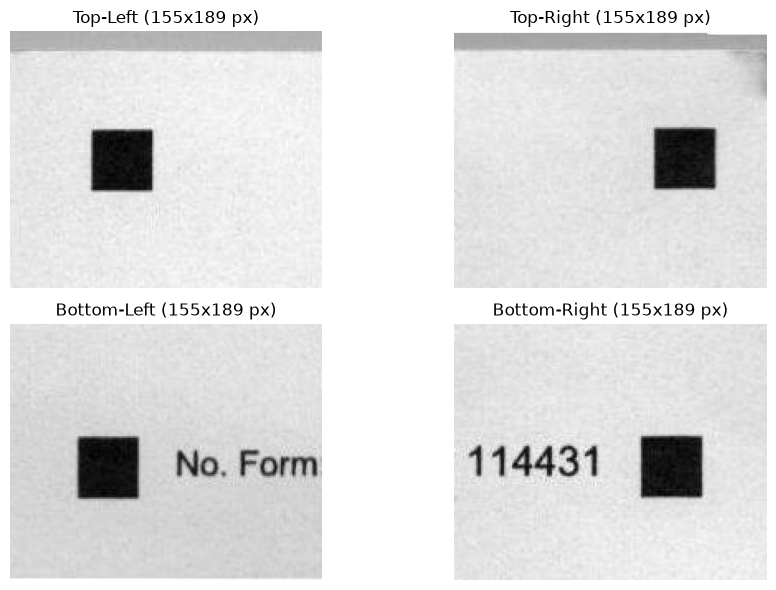

Dimensiones de la imagen: Alto = 3897, Ancho = 1260


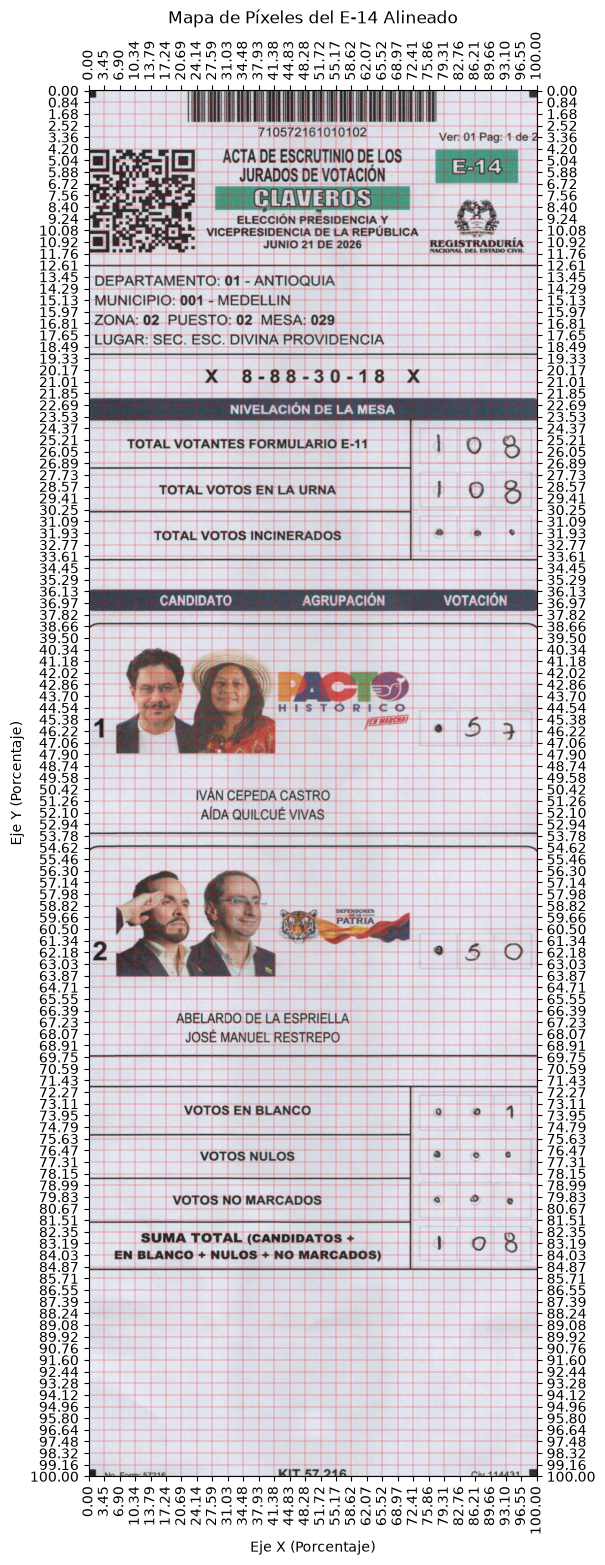

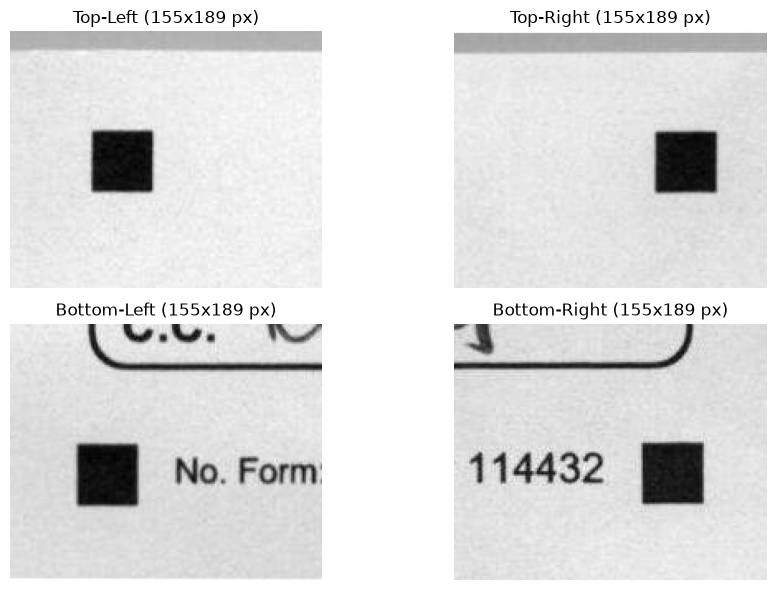

Dimensiones de la imagen: Alto = 3897, Ancho = 1260


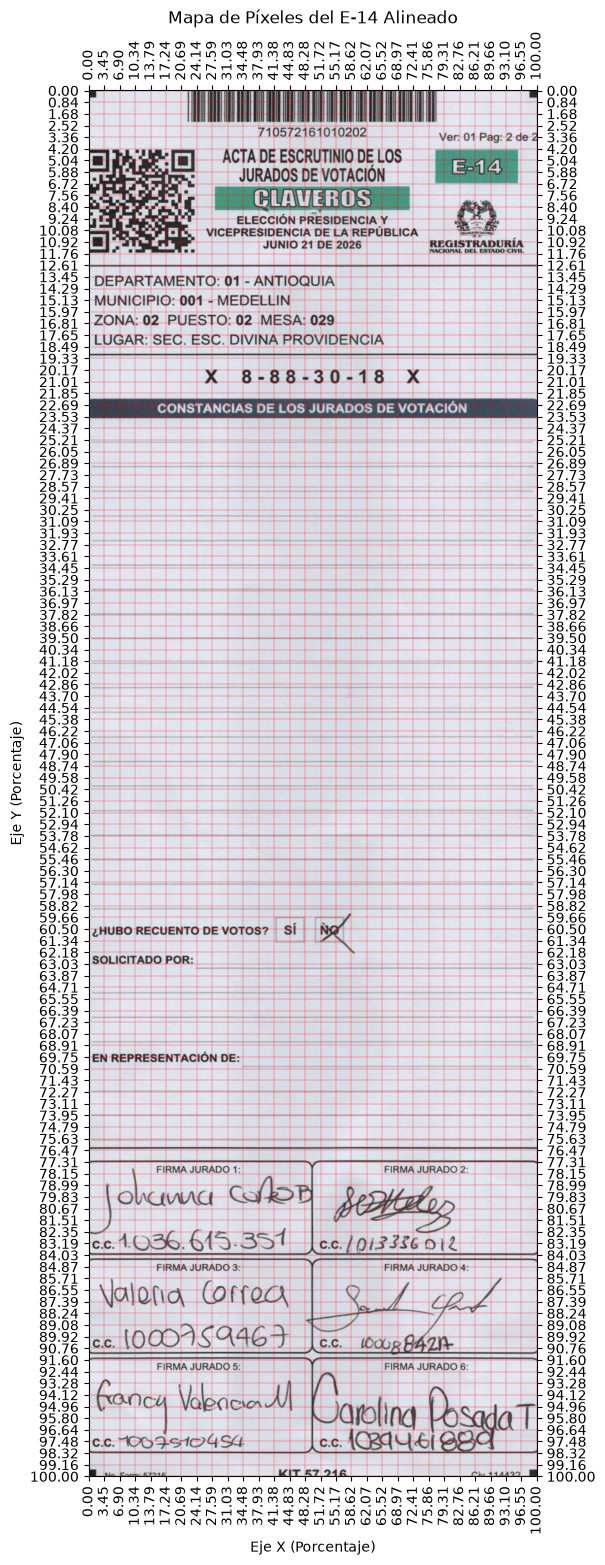


[2/4] EJECUTANDO INFERENCIA OCR / HTR / OMR...

--- DIAGNÓSTICO DE BANDERAS ---
  [FLAG] flag_baja_conf_encabezado: confianza_codigo(c1=0.57, c2=0.38)
  [FLAG] flag_baja_conf_votos: promedio=0.64; celdas_bajas=['Total_E11_1=0(0.34)', 'Total_Urna_1=0(0.32)', 'Total_Incinerados_1=0(0.39)', 'Total_Incinerados_2=0(0.27)', 'Total_Incinerados_3=0(0.25)', 'Votos_A_1=0(0.34)', 'Votos_B_1=0(0.72)', 'V_Blanco_1=0(0.17)', 'V_Blanco_2=0(0.48)', 'V_Nulos_1=0(0.34)', 'V_Nulos_2=0(0.57)', 'V_Sin_Marcar_1=0(0.35)', 'V_Sin_Marcar_3=0(0.12)', 'Suma_Total_1=0(0.29)']
  [FLAG] flag_descuadre_aritmetico: suma_candidatos=107, t_urna-t_inc=8, suma_t=8

--- ENCABEZADO Y DIVIPOLE LEÍDO ---
  Pág 1     : {'DP_Dept': '01', 'DP_Munp': '001', 'DP_Zona': '02', 'DP_Psto': '02', 'DP_Mesa': '029', 'DP_Lugr': 'SEC. ESC. DIVINA PROVIDENCIA'}
  Pág 2     : {'DP_Dept': '01', 'DP_Munp': '001', 'DP_Zona': '02', 'DP_Psto': '02', 'DP_Mesa': '029', 'DP_Lugr': 'SEC. ESC. DIVINA PROVIDENCIA'}
  Código P1 : '8883018' (s=0.57) | 

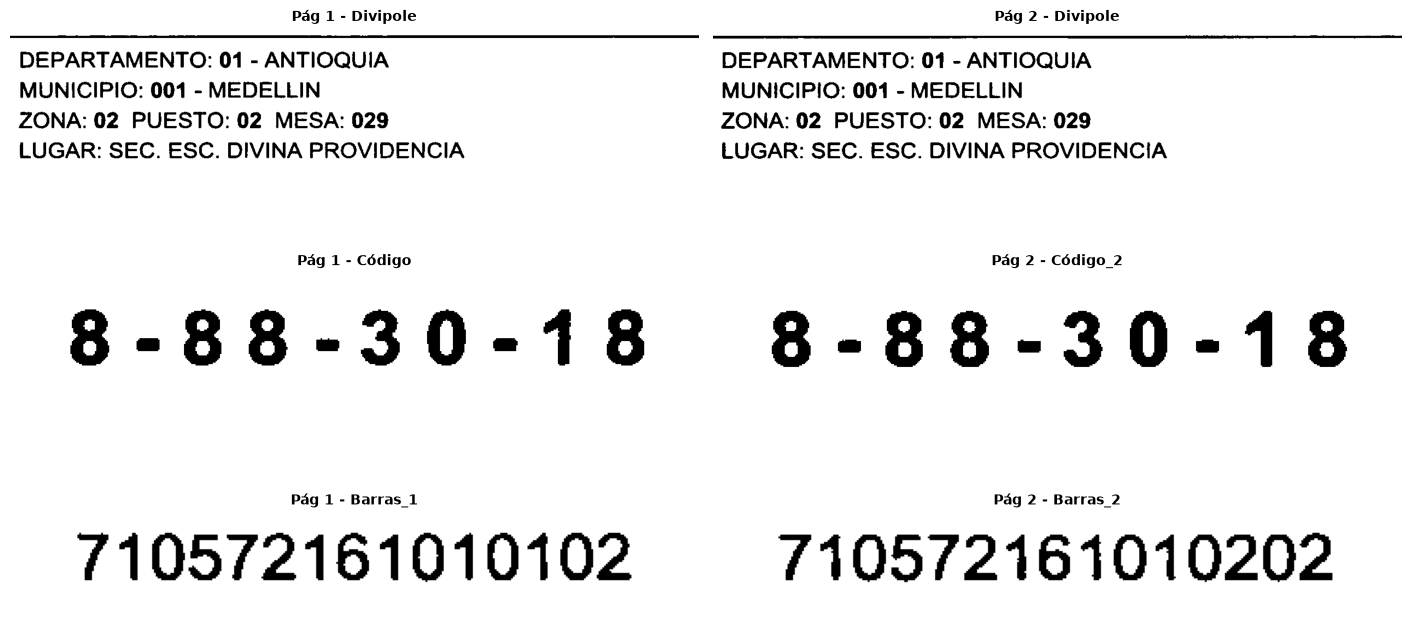


[4/4] CAPTURAS DE VOTOS MANUSCRITOS (PÁG. 1) Y AUDITORÍA OMR (PÁG. 2):


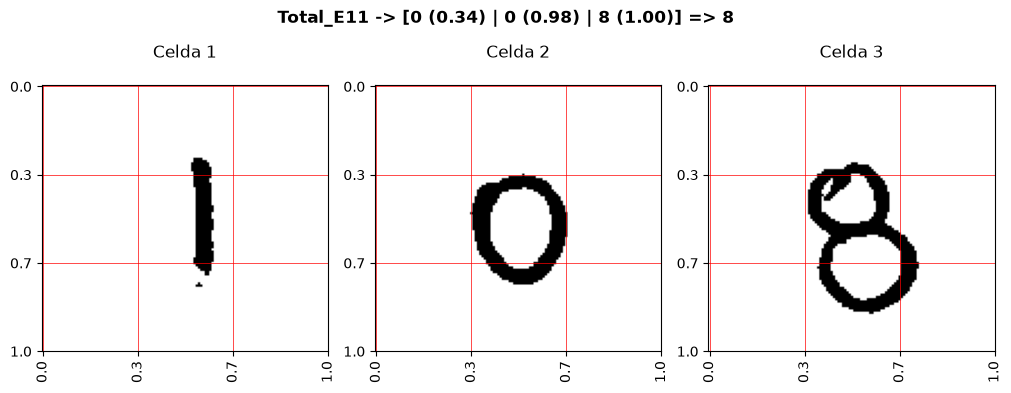

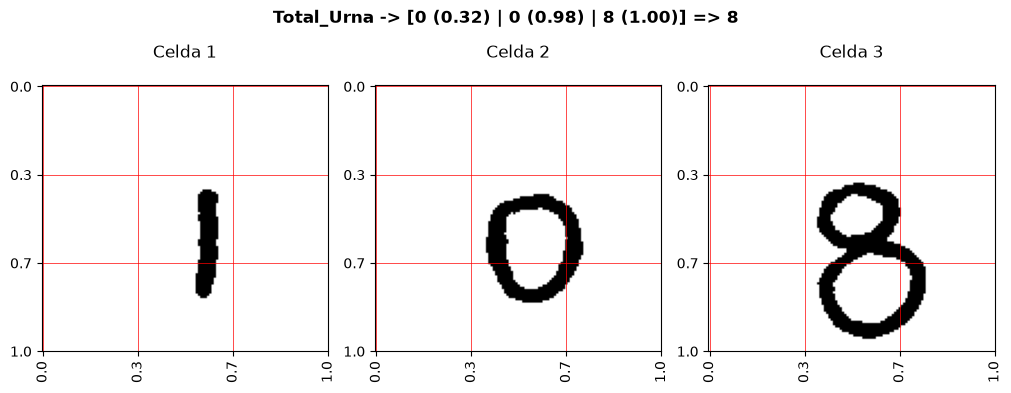

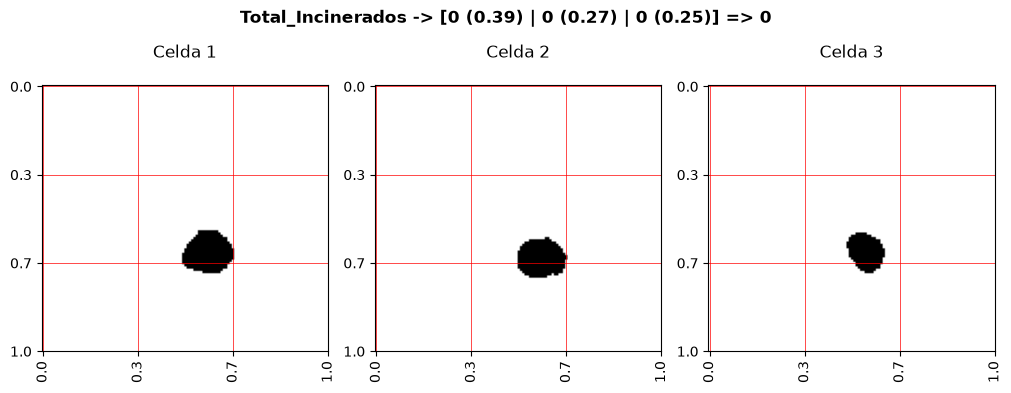

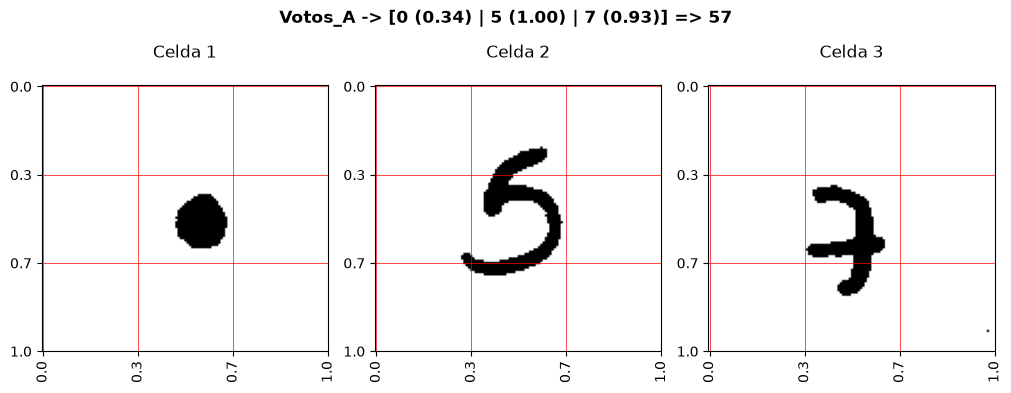

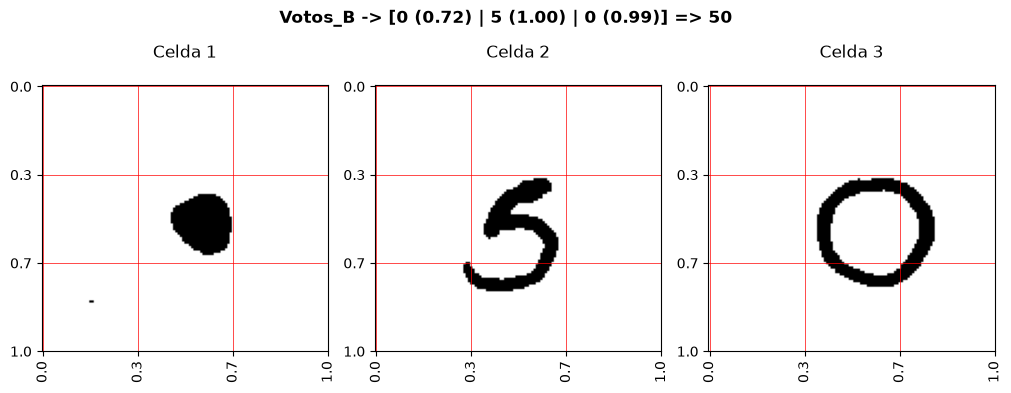

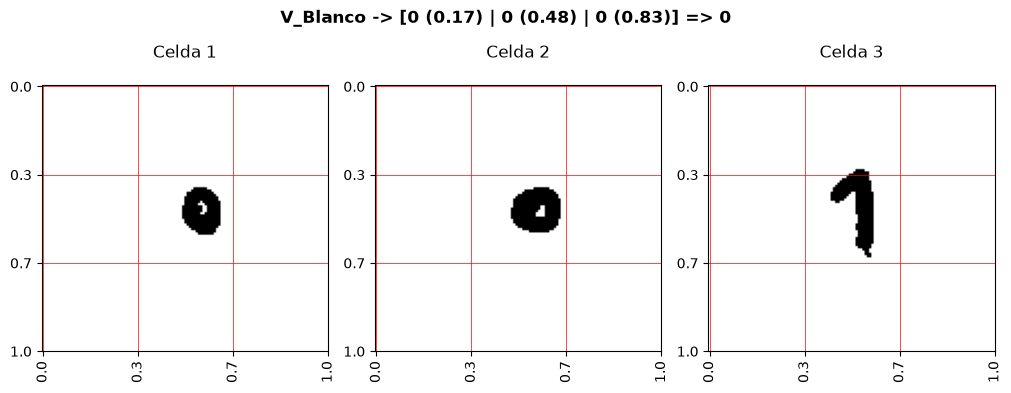

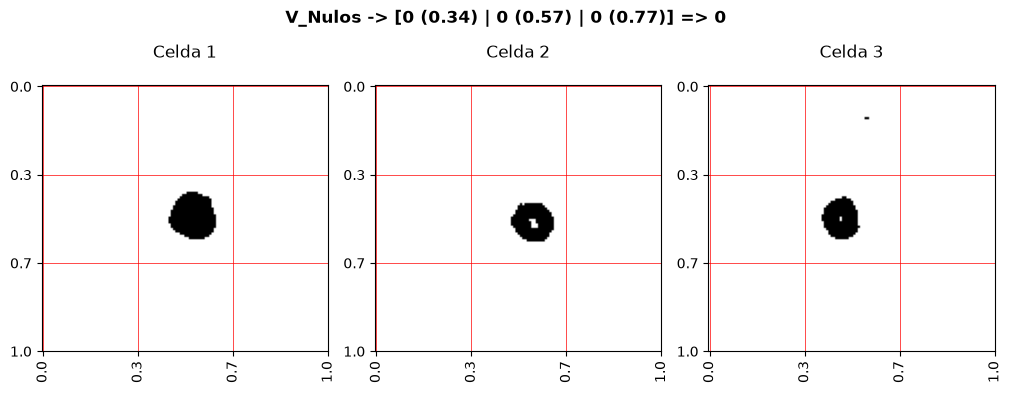

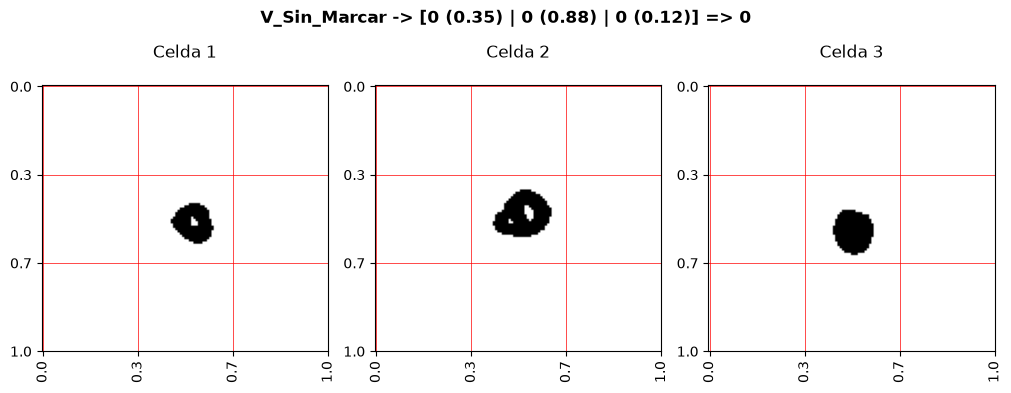

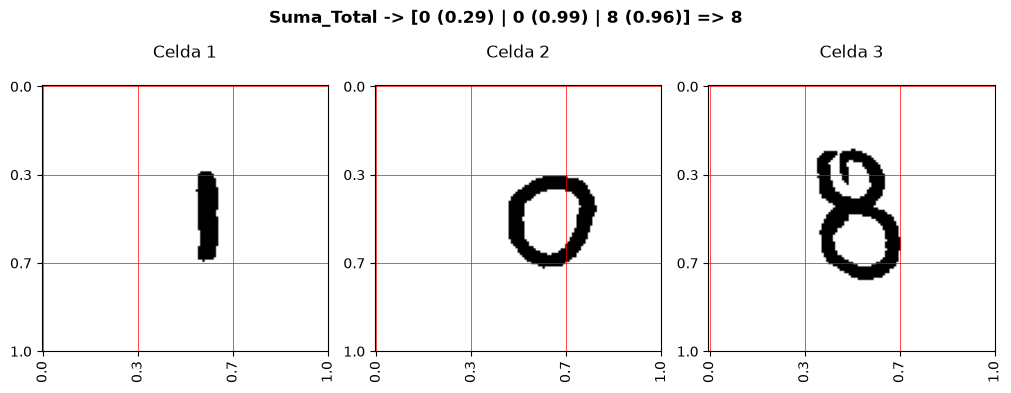

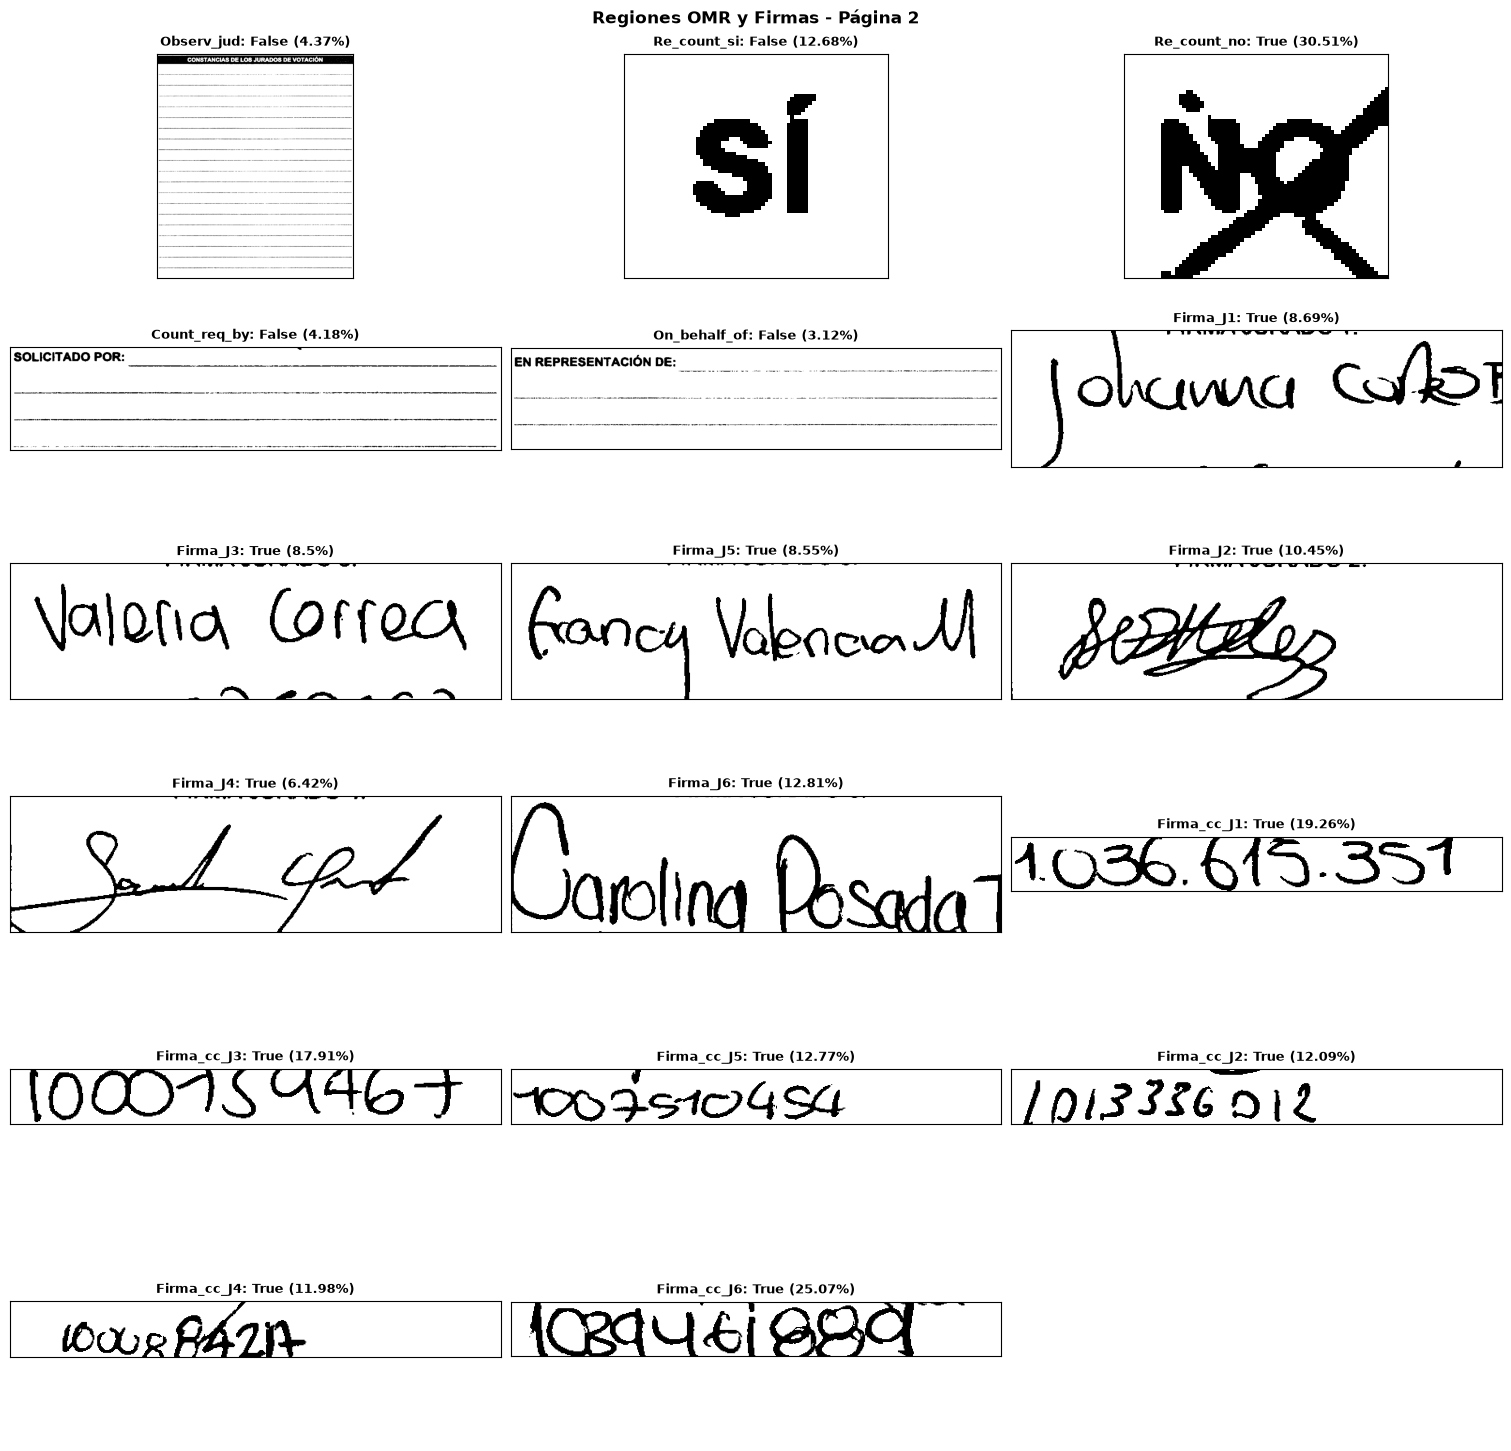

In [14]:
# CONFIGURA AQUÍ EL PDF A INSPECCIONAR:
# Puedes poner un texto (nombre o fragmento), ej: "01_172_00_00_016"
# O el número del log [N/377] ej: 43

PDF_QUERY: str | int = "01_001_02_02_029"
inspect_e14_pdf(PDF_QUERY)